# Chapter 2: Supervised Learning

## Chapter Summary
Supervised learning maps features to known targets. This chapter compares major classifiers and regressors, connects model complexity to underfitting and overfitting, and demonstrates why preprocessing and uncertainty estimates matter.

## Theoretical Deep-Dive

### Bias, variance, and generalization
An overly simple model has high bias and underfits. An overly flexible model has high variance and may memorize noise. Validation performance, not training performance alone, guides model complexity.

### Model families
- **k-NN:** local, nonparametric, and scale-sensitive.
- **Linear models:** predictions are weighted sums; regularization constrains coefficients.
- **Naive Bayes:** fast probabilistic models with conditional-independence assumptions.
- **Trees and ensembles:** nonlinear decision rules; ensembles reduce the instability of one tree.
- **Kernel SVM:** nonlinear boundaries through similarity features.
- **Neural networks:** compositions of linear transformations and nonlinear activations.

For binary logistic regression, $P(y=1|x)=\sigma(w^Tx+b)$, where $\sigma(z)=1/(1+e^{-z})$. L2 regularization penalizes large weights and trades training fit for stability.

**Book coverage:** classification/regression, generalization, k-NN, linear models, Naive Bayes, trees, ensembles, SVM, neural networks, and classifier uncertainty (Chapter 2, printed pp. 25-127).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, make_regression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, mean_squared_error

cancer = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    cancer.data, cancer.target, stratify=cancer.target, random_state=42
)
print("Cancer data:", cancer.data.shape)
print("Class counts:", dict(zip(cancer.target_names, np.bincount(cancer.target))))

Cancer data: (569, 30)
Class counts: {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}


In [2]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

rows = []
for k in [1, 3, 7, 15]:
    knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    knn.fit(X_train, y_train)
    rows.append((f"k-NN (k={k})", knn.score(X_train, y_train), knn.score(X_test, y_test)))

for c in [0.01, 1, 100]:
    logistic = make_pipeline(StandardScaler(), LogisticRegression(C=c, max_iter=3000))
    logistic.fit(X_train, y_train)
    rows.append((f"Logistic (C={c})", logistic.score(X_train, y_train), logistic.score(X_test, y_test)))

display(pd.DataFrame(rows, columns=["model", "train_accuracy", "test_accuracy"]).round(3))

,model,train_accuracy,test_accuracy
0,k-NN (k=1),1.000,0.951
1,k-NN (k=3),0.977,0.972
2,k-NN (k=7),0.974,0.979
3,k-NN (k=15),0.969,0.958
4,Logistic (C=0.01),0.958,0.937
5,Logistic (C=1),0.988,0.986
6,Logistic (C=100),0.998,0.944


In [3]:
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

models = {
    "Gaussian NB": GaussianNB(),
    "Decision tree": DecisionTreeClassifier(max_depth=4, random_state=42),
    "Random forest": RandomForestClassifier(n_estimators=150, random_state=42),
    "Gradient boosting": GradientBoostingClassifier(random_state=42),
    "RBF SVM": make_pipeline(StandardScaler(), SVC(C=2, random_state=42)),
    "MLP": make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(40,), max_iter=1500, random_state=42)),
}
comparison = []
for name, estimator in models.items():
    estimator.fit(X_train, y_train)
    comparison.append((name, estimator.score(X_train, y_train), estimator.score(X_test, y_test)))
display(pd.DataFrame(comparison, columns=["model", "train_accuracy", "test_accuracy"]).round(3))

,model,train_accuracy,test_accuracy
0,Gaussian NB,0.946,0.937
1,Decision tree,0.988,0.944
2,Random forest,1.000,0.958
3,Gradient boosting,1.000,0.958
4,RBF SVM,0.986,0.986
5,MLP,0.993,0.965


In [4]:
X_reg, y_reg = make_regression(n_samples=180, n_features=30, n_informative=8, noise=18, random_state=42)
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_reg, y_reg, random_state=42)
regression_results = []
for name, estimator in {
    "Ridge alpha=1": Ridge(alpha=1),
    "Ridge alpha=10": Ridge(alpha=10),
    "Lasso alpha=1": Lasso(alpha=1, max_iter=5000),
}.items():
    estimator.fit(Xr_train, yr_train)
    prediction = estimator.predict(Xr_test)
    regression_results.append((name, mean_squared_error(yr_test, prediction) ** 0.5, estimator.score(Xr_test, yr_test)))
display(pd.DataFrame(regression_results, columns=["model", "RMSE", "R2"]).round(3))

,model,RMSE,R2
0,Ridge alpha=1,19.494,0.983
1,Ridge alpha=10,28.587,0.964
2,Lasso alpha=1,17.978,0.986


,malignant,benign,predicted
0,0.013,0.987,benign
1,1.000,0.000,malignant
2,0.307,0.693,benign
3,0.093,0.907,benign
4,0.293,0.707,benign


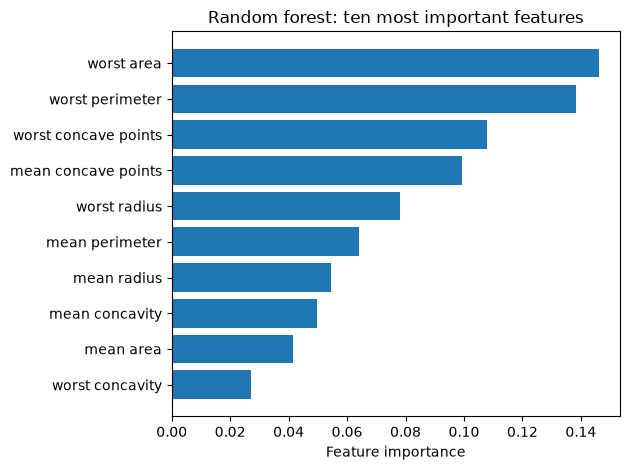

In [5]:
best = models["Random forest"]
probabilities = best.predict_proba(X_test[:5])
uncertainty = pd.DataFrame(probabilities, columns=cancer.target_names)
uncertainty["predicted"] = cancer.target_names[best.predict(X_test[:5])]
display(uncertainty.round(3))

forest = models["Random forest"]
top = np.argsort(forest.feature_importances_)[-10:]
plt.barh(cancer.feature_names[top], forest.feature_importances_[top])
plt.xlabel("Feature importance")
plt.title("Random forest: ten most important features")
plt.tight_layout(); plt.show()

## Key Takeaways
- Training score alone cannot diagnose generalization.
- Hyperparameters such as `k`, `C`, depth, and regularization strength control complexity.
- Scaling is essential for distance-, margin-, and gradient-based models.
- Ensembles usually generalize better than a single unrestricted tree.
- Probabilities and decision scores express confidence, but they are not automatically calibrated truth.